In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df_scaled = pd.read_csv(
    "../output/customer_rfm_scaled.csv",
    dtype={"Customer ID": "string"}
)

X = df_scaled[
    ["Recency", "Frequency", "Monetary"]
].copy()

print("Kích thước dữ liệu:", X.shape)
print("Giá trị thiếu:", X.isna().sum().sum())
print("Số khách hàng:", df_scaled["Customer ID"].nunique())

Kích thước dữ liệu: (5878, 3)
Giá trị thiếu: 0
Số khách hàng: 5878


In [2]:
k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    inertias.append(model.inertia_)

    score = silhouette_score(
        X,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_scores.append(score)

results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

print("KẾT QUẢ ĐÁNH GIÁ SỐ CỤM")
print(results.round(4).to_string(index=False))

KẾT QUẢ ĐÁNH GIÁ SỐ CỤM
 K   Inertia  Silhouette Score
 2 8880.1800            0.4193
 3 5716.0347            0.4010
 4 4473.0483            0.3643
 5 3627.6823            0.3709
 6 3072.3611            0.3493
 7 2726.3193            0.3337
 8 2464.1625            0.3180
 9 2282.4912            0.3125
10 2133.2880            0.2932


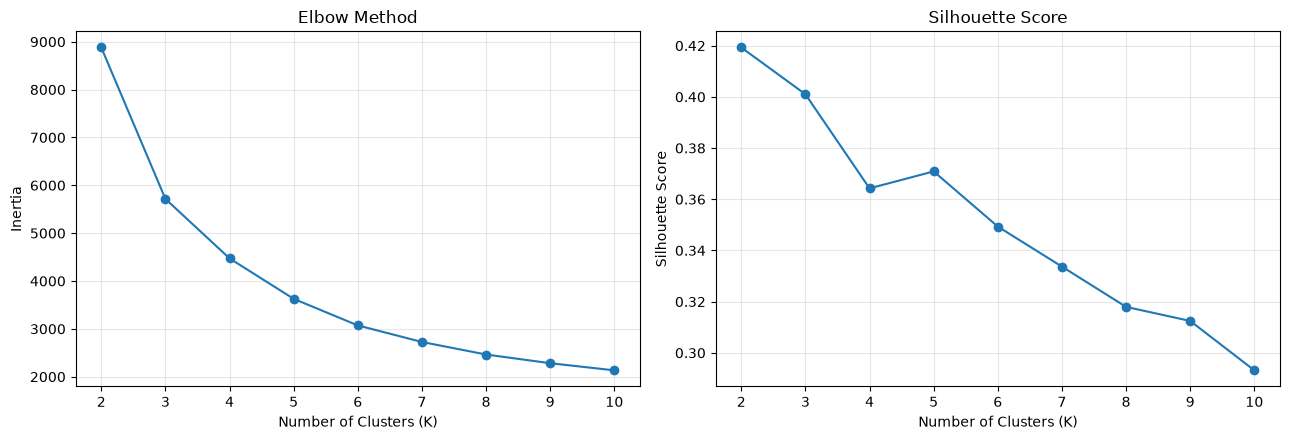

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    results["K"],
    results["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(results["K"])
axes[0].grid(alpha=0.3)

axes[1].plot(
    results["K"],
    results["Silhouette Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(results["K"])
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../output/kmeans_k_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
df_rfm_original = pd.read_csv(
    "../output/customer_rfm.csv",
    dtype={"Customer ID": "string"}
)

for k in [2, 3]:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    df_profile = df_scaled[["Customer ID"]].copy()
    df_profile["Cluster"] = labels

    df_profile = df_profile.merge(
        df_rfm_original,
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )

    profile = df_profile.groupby("Cluster").agg(
        Customers=("Customer ID", "count"),
        Recency_Median=("Recency", "median"),
        Frequency_Median=("Frequency", "median"),
        Monetary_Median=("Monetary", "median"),
        Monetary_Total=("Monetary", "sum")
    )

    profile["Customer_Percent"] = (
        profile["Customers"] / len(df_profile) * 100
    )

    print(f"\nVới K = {k}")
    print(profile.round(2).to_string())


Với K = 2
         Customers  Recency_Median  Frequency_Median  Monetary_Median  Monetary_Total  Customer_Percent
Cluster                                                                                                
0             3179           354.0               1.0           370.45      1658614.22             54.08
1             2699            31.0               7.0          2433.28     15716190.04             45.92

Với K = 3
         Customers  Recency_Median  Frequency_Median  Monetary_Median  Monetary_Total  Customer_Percent
Cluster                                                                                                
0             1839           438.0               1.0           326.25      1020888.59             31.29
1             1675            26.0              11.0          3939.24     14341267.21             28.50
2             2364            62.0               3.0           716.56      2012648.46             40.22
